# NN-Steiner: released model + congestion/delay-aware candidate selection

**Notes**

No training is launched by the new workflow. It downloads the team's released 120k-example checkpoint, reproduces a fixed wirelength baseline, then explores candidate selection under additional objectives.

The release reports 2.73% extra wire at threshold 0.9. This is a checkpoint trained by the team, not a model newly trained by you. It does not establish full-paper retraining replication.

[Released model](https://github.com/Ashilman25/nn-steiner-rsmt/releases/tag/model-120k) · : the already-trained model we downloaded, so you could skip training.

[Paper](https://arxiv.org/abs/2312.10589) · : the original research explaining NN-Steiner.

[OpenROAD routing](https://openroad.readthedocs.io/en/latest/main/src/grt/README.html) · : documentation for a real chip-routing tool that considers congestion and timing.

[OpenROAD RC estimates](https://openroad.readthedocs.io/en/latest/main/src/est/README.html) : explains estimating wire resistance and capacitance, which affect signal delay.


# 1. Mount Drive and prepare the project

The code automatically uses the CPU when no GPU is available. New computations may take longer, but matching cached candidates can be reused.

Google Drive stores the saved models and results. Colab's temporary disk holds the program files. Existing folders are preserved.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, subprocess, sys, json, hashlib, urllib.request, time
REPO=Path('/content/nn-steiner-rsmt')
DRIVE_WORK=Path('/content/drive/MyDrive/FA26CMPE257Sec02MachineLearningProject/nn-steiner-work')
if not REPO.exists():
    subprocess.run(['git','clone','https://github.com/Ashilman25/nn-steiner-rsmt.git',str(REPO)],check=True)
os.chdir(REPO)
WORK=REPO/'work'
WORK.mkdir(exist_ok=True)
for name in ('data','points','models','outputs','exp_out'):
    target=DRIVE_WORK/name
    target.mkdir(parents=True,exist_ok=True)
    link=WORK/name
    if link.is_symlink():
        assert link.resolve()==target.resolve(), f'Unexpected existing link: {link}'
    elif link.exists():
        raise RuntimeError(f'{link} is a real folder; preserve its files and resolve manually.')
    else:
        link.symlink_to(target,target_is_directory=True)
subprocess.run(['bash','scripts/setup.sh'],cwd=REPO,check=True)
print('Project ready. No training was launched.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project ready. No training was launched.


## 2. Download and verify the released checkpoint

This is the file that avoids retraining: m15_kb4_n120000.pt (829,490,575 bytes). A matching copy is also included with the downloadable deliverables.


In [ ]:
MODEL=WORK/'models/m15_kb4_n120000.pt'
EXPECTED_SHA='bbb85f476556bcb95ad811457f7056e0dfa2173d10dc804ba88561bee1e5c2b5'
URL='https://github.com/Ashilman25/nn-steiner-rsmt/releases/download/model-120k/m15_kb4_n120000.pt'
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
if not MODEL.is_file():
    temporary=Path('/content/m15_kb4_n120000.download')
    urllib.request.urlretrieve(URL,temporary)
    assert temporary.stat().st_size==829490575, 'Unexpected download size'
    assert file_sha(temporary)==EXPECTED_SHA, 'Download checksum mismatch'
    import shutil
    shutil.copyfile(temporary,MODEL)
assert MODEL.stat().st_size==829490575
assert file_sha(MODEL)==EXPECTED_SHA
print('Released model verified:',MODEL)


Released model verified: /content/nn-steiner-rsmt/work/models/m15_kb4_n120000.pt


## 3. Fixed 100-problem wirelength baseline

Use threshold 0.9 as documented for this checkpoint. The authors' original checkpoint uses a different recommended threshold. These are distinct models.


In [ ]:
OUT=WORK/'exp_out/congestion_delay_extension_v1'
OUT.mkdir(parents=True,exist_ok=True)
BASE_STEM=OUT/'released120k_baseline_100'
cmd=['bash','scripts/arora.sh','scale','flow=[nn_exp]',
     f'nn_exp.model={MODEL}','nn_exp.threshold=0.9',
     'nn_exp.test_set=upstream/points/point100_10000x10000-uniform-100-pt/',
     f'nn_exp.output={BASE_STEM}']
subprocess.run(cmd,cwd=REPO,check=True)
subprocess.run([sys.executable,'third_party/NN-Steiner/evaluator/evaluateRatio.py',
                str(BASE_STEM)+'-solved.txt',
                'third_party/NN-Steiner/exp_out/100_10000x10000-uniform-golden.txt'],
               cwd=REPO,check=True)


CompletedProcess(args=['/usr/bin/python3', 'third_party/NN-Steiner/evaluator/evaluateRatio.py', '/content/nn-steiner-rsmt/work/exp_out/congestion_delay_extension_v1/released120k_baseline_100-solved.txt', 'third_party/NN-Steiner/exp_out/100_10000x10000-uniform-golden.txt'], returncode=0)

In [ ]:
score = subprocess.run(
    [
        sys.executable,
        "third_party/NN-Steiner/evaluator/evaluateRatio.py",
        str(BASE_STEM) + "-solved.txt",
        "third_party/NN-Steiner/exp_out/100_10000x10000-uniform-golden.txt",
    ],
    cwd=REPO,
    check=True,
    capture_output=True,
    text=True,
)

print(score.stdout)

average error percentage of 100 cases: 2.7304



## 4. Multi-objective candidate selection

We extend NN-Steiner by changing **how we select a tree**, while keeping the pretrained neural-network weights fixed. No retraining is performed.

The network generates several candidate trees using different thresholds and orientations. All candidates are evaluated in the original coordinate system, using the same fixed congestion background and signal source.

### Combined objective

For each problem, we select a candidate using:

$$
J =
\alpha \frac{L}{L_0}
+\beta \frac{C}{\max(Q_0,1)}
+\gamma \frac{D}{\max(D_0,\epsilon)}.
$$

Here, $\alpha$, $\beta$, and $\gamma$ control the importance of wirelength, congestion, and delay. Normalization allows terms with different units to be combined.

### Wirelength

$L$ is the total Manhattan length of the tree's electrical edges.

$L_0$ is the baseline wirelength obtained without input rotation, using the released model's recommended threshold of **0.9**.

### Congestion proxy

The routing area is divided into horizontal and vertical grid bins. We penalize the additional squared overflow caused by a candidate:

$$
C =
\sum_b \left[
\max(0,B_b+q_b-K_b)^2
-\max(0,B_b-K_b)^2
\right].
$$

For each directional bin $b$:

- $B_b$ is the fixed synthetic background demand.
- $K_b$ is the assumed capacity.
- $q_b$ is candidate segment length inside the bin divided by bin width.

$Q_0$ is the baseline's total wire density, used for normalization.

This is a **wire-density overflow proxy**, not a measurement from a technology-aware physical router.

### Delay proxy

$D$ is the worst source-to-sink **Elmore RC delay estimate** on the electrical tree.

The estimate uses synthetic driver resistance, wire resistance and capacitance, and sink loads. $D_0$ is the baseline delay, and $\epsilon$ prevents division by zero.

We assume:

- Terminal 0 is the signal source, or **driver**.
- All other terminals have equal sink loads.
- Delay is expressed in arbitrary units, **not nanoseconds**.

Testing other drivers and electrical parameters is necessary before making broader claims.

### Wirelength constraint

A selected candidate must satisfy:

$$
L \leq 1.10L_0.
$$

This limits additional wirelength to **10% above the original baseline**.

### Routing assumptions

An edge whose endpoints differ in both coordinates is represented by either:

- **HV:** horizontal first, then vertical.
- **VH:** vertical first, then horizontal.

Crossings are treated as electrically insulated. Coincident segments are counted separately for each electrical edge, preserving the original tree's electrical topology.

Routing layers and vias are not modeled. Therefore, the visualization is a **routing abstraction**, not a verified legal single-layer layout.

### Fair comparison

We compare four selection policies:

1. **Wirelength-only:** considers wirelength.
2. **Congestion-aware:** considers wirelength and congestion.
3. **Delay-aware:** considers wirelength and delay.
4. **Combined:** considers all three objectives.

All four policies use the **same candidate pool**, including the original baseline. This helps distinguish the benefit of the new objective from the benefit of trying more candidate trees.

A lower weighted score alone does not prove better physical routing. We report each metric, validity, computation time, and tradeoff separately. Conclusions apply to the tested synthetic conditions.

In [ ]:
# Scoring code lives in lib/routing_objectives.py
MODULE_PATH=REPO/'lib/routing_objectives.py'
assert MODULE_PATH.is_file(), 'Scorer missing: pull the latest code (step 1).'
MODULE_SOURCE=MODULE_PATH.read_text()
if str(REPO/'lib') not in sys.path: sys.path.insert(0,str(REPO/'lib'))
import importlib
import routing_objectives as ro
ro=importlib.reload(ro)
print('Loaded experimental scorer:',MODULE_PATH)


## 5. Configure the experiment

>Start with `PILOT=True` to check the code on **2 problems, 1 congestion
scenario, and 8 candidates per problem**.

>Then set `PILOT=False` for **10 problems, 3 congestion scenarios, and 24 candidates per problem**.

>Keep objective weights fixed during testing. Use separate development data if tuning is needed.

>No retraining occurs, but more candidates take longer to generate. These synthetic experiments are exploratory; use fresh test problems to assess generalization.


In [ ]:
# PILOT=True
PILOT=False
N_CASES=2 if PILOT else 10
TURNS=(0,1) if PILOT else (0,1,2,3)
THRESHOLDS=(0.9,0.95) if PILOT else (0.7,0.9,0.95)
SCENARIO_SEEDS=(201,) if PILOT else (201,202,203)
POLICIES={
    'wire_only':(1.0,0.0,0.0),
    'congestion_aware':(1.0,1.0,0.0),
    'delay_aware':(1.0,0.0,1.0),
    'combined':(1.0,1.0,1.0),
}
WIRELENGTH_BUDGET=0.10
POINT_DIR=REPO/'third_party/NN-Steiner/points/point100_10000x10000-uniform-100-pt'
# Files sort by name (uniform-0, 1, 10, 11, ...). Batch 1 used FIRST_CASE=0, batch 2 used 10.
FIRST_CASE=10
point_files=sorted(p for p in POINT_DIR.iterdir() if p.is_file())[FIRST_CASE:FIRST_CASE+N_CASES]
assert len(point_files)==N_CASES
CACHE=OUT/'candidate_cache'
CACHE.mkdir(exist_ok=True)
software_fingerprint=hashlib.sha256()
for folder in (REPO/'third_party/NN-Steiner/arora',REPO/'lib'):
    for file in sorted(folder.rglob('*.py')):
        software_fingerprint.update(str(file.relative_to(REPO)).encode())
        software_fingerprint.update(file.read_bytes())
EXPERIMENT={
    'model_sha256':EXPECTED_SHA,'module_sha256':hashlib.sha256(MODULE_SOURCE.encode()).hexdigest(),
    'source_sha256':software_fingerprint.hexdigest(),
    'wrapper_revision':subprocess.check_output(['git','rev-parse','HEAD'],cwd=REPO,text=True).strip(),
    'thresholds':THRESHOLDS,'turns':TURNS,'seeds':SCENARIO_SEEDS,'policies':POLICIES,
    'wirelength_budget':WIRELENGTH_BUDGET,
    'cases':[p.name for p in point_files],
    'warning':'synthetic proxies; no training, real layer assignment, vias, buffering, or signoff STA',
}
RUN_ID=hashlib.sha256(json.dumps(EXPERIMENT,sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR=OUT/RUN_ID
RUN_DIR.mkdir(exist_ok=True)
(RUN_DIR/'experiment.json').write_text(json.dumps(EXPERIMENT,indent=2))
print('Run folder:',RUN_DIR)


Run folder: /content/nn-steiner-rsmt/work/exp_out/congestion_delay_extension_v1/fdebffaf35a410fc


In [ ]:
print("Pilot:", PILOT)
print("Problems:", len(point_files))
print("Scenarios:", SCENARIO_SEEDS)

Pilot: False
Problems: 10
Scenarios: (201, 202, 203)


## 6. Generate frozen-model proposals and select with each objective

When rotating the input points, keep the congestion map fixed. Think of it as a map of busy areas—the busy areas stay in the same place.

We compare three approaches:
- Original model: solves the problem once.
- Wirelength-only selection: tries several trees and picks the shortest.
- Our new method: tries the same trees but also considers congestion and delay.

This helps us see whether improvements come from our new objective or simply from trying more trees.

In [ ]:
import pandas as pd
rows=[]
for point_file in point_files:
    spec={'model':EXPECTED_SHA,'code':EXPERIMENT['source_sha256'],
          'module':EXPERIMENT['module_sha256'],'point_sha256':file_sha(point_file),
          'thresholds':THRESHOLDS,'turns':TURNS}
    key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
    cache_file=CACHE/(key+'.json')
    if cache_file.is_file():
        saved=json.loads(cache_file.read_text())
        candidates=saved['candidates']
        generation_seconds=saved['generation_seconds']
    else:
        begin=time.monotonic()
        candidates=ro.generate_candidates(REPO,point_file,MODEL,THRESHOLDS,TURNS)
        generation_seconds=time.monotonic()-begin
        saved={'spec':spec,'generation_seconds':generation_seconds,'candidates':candidates}
        temp=CACHE/(key+'.tmp')
        temp.write_text(json.dumps(saved));temp.replace(cache_file)
    print(point_file.name, 'candidates:',len(candidates),flush=True)
    for seed in SCENARIO_SEEDS:
        sc=ro.scenario(seed=seed)
        (RUN_DIR/f'scenario_{seed}.json').write_text(json.dumps(sc))
        for candidate in candidates:
            candidate['metrics']=ro.metrics(candidate['tree'],sc,candidate['bend'])
        baseline=next(c for c in candidates if c['id']=='turn0-t0.9-HV')
        normalizers=ro.scales(baseline['metrics'],sc)
        rows.append({'problem':point_file.name,'scenario_seed':seed,'policy':'original_baseline',
                     'candidate':baseline['id'],**baseline['metrics'],
                     'selected_cost':None,'baseline_cost_same_weights':None,
                     'candidate_generation_seconds':generation_seconds})
        for policy,weights in POLICIES.items():
            selected,cost,normalizers=ro.choose(candidates,sc,weights,wirelength_budget=WIRELENGTH_BUDGET)
            baseline_cost=ro.objective(baseline['metrics'],normalizers,weights)
            assert cost<=baseline_cost+1e-8
            rows.append({'problem':point_file.name,'scenario_seed':seed,'policy':policy,
                         'candidate':selected['id'],**selected['metrics'],
                         'selected_cost':cost,'baseline_cost_same_weights':baseline_cost,
                         'candidate_generation_seconds':generation_seconds})
            selection_path=RUN_DIR/f'{point_file.stem}_seed{seed}_{policy}.json'
            selection_path.write_text(json.dumps({'selection':selected,'normalizers':normalizers,
                                                 'weights':weights,'scenario':sc},indent=2))
    pd.DataFrame(rows).to_csv(RUN_DIR/'per_case_results.csv',index=False)
results=pd.DataFrame(rows)
display(results)


point100_10000x10000-uniform-18.txt candidates: 24
point100_10000x10000-uniform-19.txt candidates: 24
point100_10000x10000-uniform-2.txt candidates: 24
point100_10000x10000-uniform-20.txt candidates: 24
point100_10000x10000-uniform-21.txt candidates: 24
point100_10000x10000-uniform-22.txt candidates: 24
point100_10000x10000-uniform-23.txt candidates: 24
point100_10000x10000-uniform-24.txt candidates: 24
point100_10000x10000-uniform-25.txt candidates: 24
point100_10000x10000-uniform-26.txt candidates: 24


,problem,scenario_seed,policy,candidate,wirelength,congestion_proxy,peak_utilization_proxy,density_sum,delay_proxy,worst_driver_sink_path,selected_cost,baseline_cost_same_weights,candidate_generation_seconds
0,point100_10000x10000-uniform-18.txt,201,original_baseline,turn0-t0.9-HV,73802.0,14.200961,1.351401,118.0832,186.958595,21069.0,NaN,NaN,28.613488
1,point100_10000x10000-uniform-18.txt,201,wire_only,turn2-t0.9-HV,73560.0,12.692913,1.254460,117.6960,179.245602,17188.0,0.996721,1.000000,28.613488
2,point100_10000x10000-uniform-18.txt,201,congestion_aware,turn0-t0.9-VH,73802.0,11.080279,1.255801,118.0832,186.958595,21069.0,1.093835,1.120262,28.613488
3,point100_10000x10000-uniform-18.txt,201,delay_aware,turn1-t0.95-HV,74254.0,12.179372,1.262084,118.8064,175.306887,18037.0,1.943802,2.000000,28.613488
4,point100_10000x10000-uniform-18.txt,201,combined,turn1-t0.95-HV,74254.0,12.179372,1.262084,118.8064,175.306887,18037.0,2.046944,2.120262,28.613488
...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,point100_10000x10000-uniform-26.txt,203,original_baseline,turn0-t0.9-HV,76997.0,8.569850,1.381593,123.1952,166.487966,19224.0,NaN,NaN,21.801331
146,point100_10000x10000-uniform-26.txt,203,wire_only,turn1-t0.95-HV,75975.0,6.244814,1.261394,121.5600,164.888505,19112.0,0.986727,1.000000,21.801331
147,point100_10000x10000-uniform-26.txt,203,congestion_aware,turn2-t0.9-HV,76142.0,5.166810,1.261394,121.8272,189.701369,25449.0,1.030836,1.069563,21.801331
148,point100_10000x10000-uniform-26.txt,203,delay_aware,turn1-t0.95-HV,75975.0,6.244814,1.261394,121.5600,164.888505,19112.0,1.977120,2.000000,21.801331


## 7. Compare components, we do not compare costs across different weights

We average all scenarios within a problem first. Then compute uncertainty over problems; counting repeated scenarios for the same pointset as independent problems would exaggerate confidence. A two-problem pilot is too small for a scientific conclusion.


**Shows how each approach performs on wirelength, congestion, and estimated delay. It helps us see what improved and what got worse.**

,wirelength,congestion_proxy,delay_proxy,peak_utilization_proxy
policy,,,,
combined,76161.500000,10.554336,197.159524,1.279536
congestion_aware,75774.266667,9.406101,220.168240,1.261737
delay_aware,76166.100000,10.951518,197.130566,1.276788
original_baseline,76462.900000,11.509866,213.308961,1.307483
wire_only,75554.600000,10.916982,222.219351,1.276316


,policy,metric,mean_difference,standard_error_over_problems,independent_problems
0,wire_only,wirelength,-908.300000,185.248845,10
1,wire_only,congestion_proxy,-0.592883,0.654211,10
2,wire_only,delay_proxy,8.910390,11.973442,10
3,wire_only,peak_utilization_proxy,-0.031167,0.020319,10
4,congestion_aware,wirelength,-688.633333,202.558715,10
5,congestion_aware,congestion_proxy,-2.103764,0.485956,10
6,congestion_aware,delay_proxy,6.859279,9.416060,10
7,congestion_aware,peak_utilization_proxy,-0.045746,0.014922,10
8,delay_aware,wirelength,-296.800000,248.587288,10
9,delay_aware,congestion_proxy,-0.558347,0.688143,10


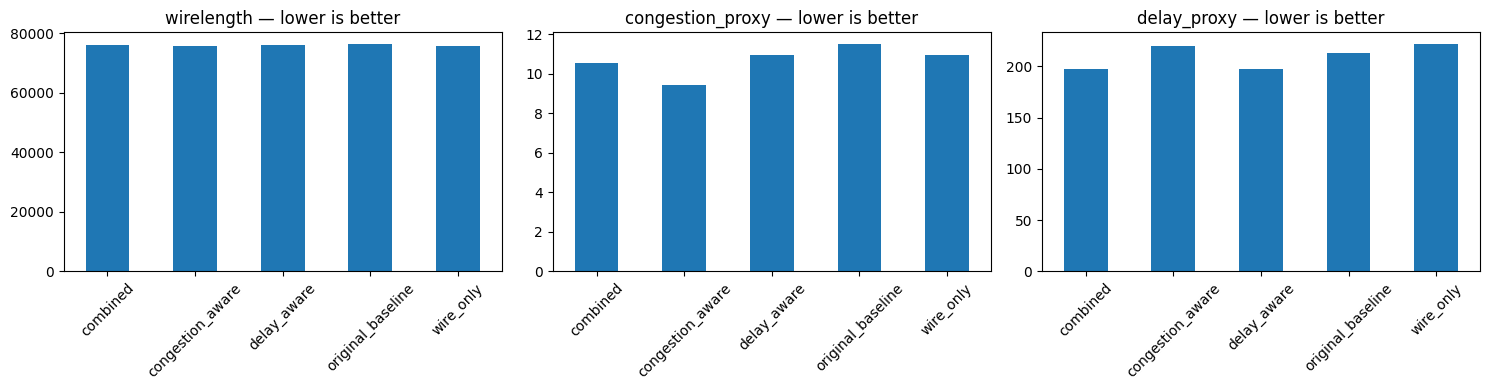

In [ ]:
metrics_to_report=['wirelength','congestion_proxy','delay_proxy','peak_utilization_proxy']
summary=results.groupby('policy')[metrics_to_report].mean()
summary.to_csv(RUN_DIR/'component_summary.csv')
display(summary)
# Paired differences over independent problem units, after averaging scenarios.
paired=[]
for policy in POLICIES:
    a=results[results.policy==policy].groupby('problem')[metrics_to_report].mean()
    b=results[results.policy=='original_baseline'].groupby('problem')[metrics_to_report].mean()
    delta=a-b
    for metric in metrics_to_report:
        paired.append({'policy':policy,'metric':metric,'mean_difference':delta[metric].mean(),
                       'standard_error_over_problems':delta[metric].std(ddof=1)/(len(delta)**0.5),
                       'independent_problems':len(delta)})
paired_table=pd.DataFrame(paired)
paired_table.to_csv(RUN_DIR/'paired_differences.csv',index=False)
display(paired_table)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,metrics_to_report[:3]):
    summary[metric].plot.bar(ax=ax)
    ax.set_title(metric+' — lower is better');ax.set_xlabel('');ax.tick_params(axis='x',rotation=45)
fig.tight_layout();fig.savefig(RUN_DIR/'objective_tradeoffs.png',dpi=180)
plt.show()


In [ ]:
#check how consistently your combined method beats wirelength-only selection. We know the averages; now we’ll count how many problems improved.
metrics = ["wirelength", "congestion_proxy", "delay_proxy"]

# Average the three scenarios within each problem.
per_problem = (
    results.groupby(["problem", "policy"])[metrics]
    .mean()
    .unstack("policy")
)

comparison = []

for metric in metrics:
    combined = per_problem[(metric, "combined")]
    wire_only = per_problem[(metric, "wire_only")]

    difference = combined - wire_only

    comparison.append({
        "metric": metric,
        "mean_difference": difference.mean(),
        "standard_error": (
            difference.std(ddof=1) / len(difference)**0.5
        ),
        "problems_improved": int((difference < -1e-8).sum()),
        "problems_tied": int((difference.abs() <= 1e-8).sum()),
        "problems_worse": int((difference > 1e-8).sum()),
        "total_problems": len(difference),
    })

comparison = pd.DataFrame(comparison)
comparison.to_csv(
    RUN_DIR / "combined_vs_wire_only.csv",
    index=False
)

display(comparison)

,metric,mean_difference,standard_error,problems_improved,problems_tied,problems_worse,total_problems
0,wirelength,606.900000,175.345592,0,2,8,10
1,congestion_proxy,-0.362646,0.546480,6,1,3,10
2,delay_proxy,-25.059827,9.853360,8,2,0,10


## 8. Display one chosen routing abstraction

This plot shows HV/VH paths and a synthetic background map. Crossings are electrically insulated in our model. A picture is not verification of legal routing or actual layer availability.


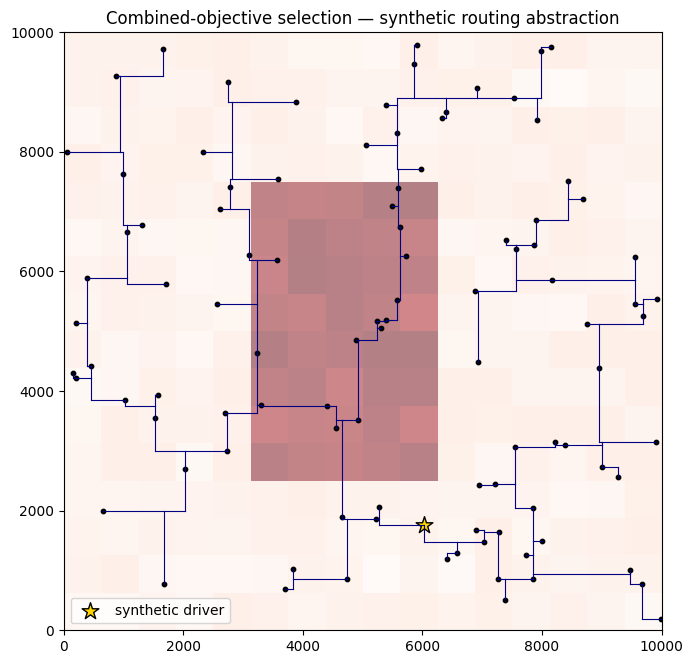

In [ ]:
chosen_file=next(RUN_DIR.glob('*_combined.json'))
chosen=json.loads(chosen_file.read_text())
fig,ax=plt.subplots(figsize=(7,7))
sc=chosen['scenario'];tree=chosen['selection']['tree'];bend=chosen['selection']['bend']
background=[[max(sc['background'][0][iy][ix],sc['background'][1][iy][ix])
             for ix in range(sc['bins'])] for iy in range(sc['bins'])]
ax.imshow(background,origin='lower',extent=(0,sc['extent'],0,sc['extent']),cmap='Reds',alpha=.5)
for (x,y),(u,v) in ro.segments(tree,bend):ax.plot([x,u],[y,v],color='navy',linewidth=.8)
terminals=tree['points'][:tree['num_terminals']]
ax.scatter([p[0] for p in terminals],[p[1] for p in terminals],s=10,c='black')
root=terminals[sc['driver_terminal']]
ax.scatter([root[0]],[root[1]],marker='*',s=160,c='gold',edgecolors='black',label='synthetic driver')
ax.set_title('Combined-objective selection — synthetic routing abstraction')
ax.legend();fig.tight_layout();fig.savefig(RUN_DIR/'selected_route.png',dpi=180)
plt.show()


**Shows the selected tree: black dots are connection points, blue lines are wires, the yellow star is the signal source, and darker red areas are busier.**

## 9. Combine both ten-problem batches

Run sections 5–8 once with `FIRST_CASE=0` and once with `FIRST_CASE=10`. This cell then pairs the two runs (same settings, different problems) into one 20-problem report.

AVERAGE RESULTS — 20 problems


,wirelength,congestion_proxy,delay_proxy
policy,,,
combined,75953.550000,11.679788,186.093874
congestion_aware,75624.633333,10.600398,211.475205
delay_aware,75956.250000,12.192592,186.031722
original_baseline,76273.500000,12.413607,204.099443
wire_only,75362.250000,12.101461,208.857427


COMBINED VS WIRE-ONLY — negative change means lower/better


,metric,change_in_group_mean_pct,mean_difference,95% CI lower,95% CI upper,problems_improved,problems_tied,problems_worse
0,wirelength,0.784610,591.300000,359.032626,823.567374,0,2,18
1,congestion_proxy,-3.484480,-0.421673,-1.094991,0.251645,12,1,7
2,delay_proxy,-10.899087,-22.763553,-35.486181,-10.040925,18,2,0


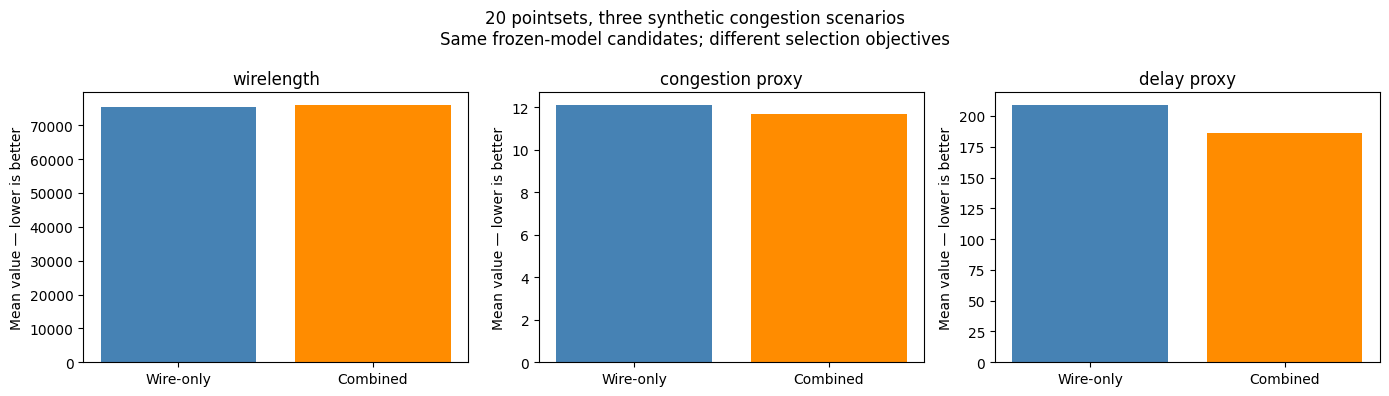

Source runs:
fdebffaf35a410fc
7adc6f9e19fb08b8

Saved final tables and chart to: /content/nn-steiner-rsmt/work/exp_out/congestion_delay_extension_v1/final_20_problem_report


In [ ]:
#combine the two ten-problem batches, leave out the pilot, and save a final table and chart.
from pathlib import Path
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = WORK / "exp_out/congestion_delay_extension_v1"

# Find completed ten-problem runs.
runs = []

for folder in root.iterdir():
    config_file = folder / "experiment.json"
    results_file = folder / "per_case_results.csv"

    if not (config_file.is_file() and results_file.is_file()):
        continue

    config = json.loads(config_file.read_text())
    data = pd.read_csv(results_file)

    if len(config["cases"]) != 10:
        continue

    # Check that every problem/scenario has every policy.
    expected_policies = set(config["policies"]) | {"original_baseline"}
    expected = set(itertools.product(
        config["cases"], config["seeds"], expected_policies
    ))
    actual = set(data[
        ["problem", "scenario_seed", "policy"]
    ].itertuples(index=False, name=None))

    if actual != expected or len(data) != len(expected):
        continue

    runs.append((folder, config, data))

# Choose the latest pair with matching settings and different problems.
runs.sort(key=lambda item: item[0].stat().st_mtime, reverse=True)

pair = None

for a, b in itertools.combinations(runs, 2):
    settings_a = {k: v for k, v in a[1].items() if k != "cases"}
    settings_b = {k: v for k, v in b[1].items() if k != "cases"}

    different_problems = set(a[1]["cases"]).isdisjoint(b[1]["cases"])

    if settings_a == settings_b and different_problems:
        pair = (a, b)
        break

assert pair is not None, (
    "Could not find two complete, compatible ten-problem batches."
)

combined_data = pd.concat(
    [item[2] for item in pair], ignore_index=True
)

assert combined_data["problem"].nunique() == 20

final_dir = root / "final_20_problem_report"
final_dir.mkdir(exist_ok=True)

combined_data.to_csv(final_dir / "all_results.csv", index=False)

(final_dir / "source_runs.json").write_text(json.dumps(
    [str(item[0]) for item in pair], indent=2
))

metrics = ["wirelength", "congestion_proxy", "delay_proxy"]

# Average scenarios within each problem first.
per_problem = (
    combined_data
    .groupby(["problem", "policy"])[metrics]
    .mean()
)

summary = per_problem.groupby("policy").mean()
summary.to_csv(final_dir / "policy_summary.csv")

print("AVERAGE RESULTS — 20 problems")
display(summary)

# Compare combined selection with equal-candidate wire-only selection.
combined = per_problem.xs("combined", level="policy")
wire_only = per_problem.xs("wire_only", level="policy")

comparison_rows = []

for metric in metrics:
    difference = combined[metric] - wire_only[metric]
    mean_difference = difference.mean()
    se = difference.std(ddof=1) / np.sqrt(len(difference))

    comparison_rows.append({
        "metric": metric,
        "change_in_group_mean_pct":
            100 * (combined[metric].mean() / wire_only[metric].mean() - 1),
        "mean_difference": mean_difference,
        "95% CI lower": mean_difference - 2.093 * se,
        "95% CI upper": mean_difference + 2.093 * se,
        "problems_improved": int((difference < -1e-8).sum()),
        "problems_tied": int((difference.abs() <= 1e-8).sum()),
        "problems_worse": int((difference > 1e-8).sum()),
    })

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(final_dir / "combined_vs_wire_only.csv", index=False)

print("COMBINED VS WIRE-ONLY — negative change means lower/better")
display(comparison)

# Separate panels because the metrics have different units.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, metrics):
    values = [
        wire_only[metric].mean(),
        combined[metric].mean()
    ]
    ax.bar(["Wire-only", "Combined"], values,
           color=["steelblue", "darkorange"])
    ax.set_title(metric.replace("_", " "))
    ax.set_ylabel("Mean value — lower is better")

fig.suptitle(
    "20 pointsets, three synthetic congestion scenarios\n"
    "Same frozen-model candidates; different selection objectives"
)
fig.tight_layout()
fig.savefig(final_dir / "final_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

print("Source runs:")
for item in pair:
    print(item[0].name)

print("\nSaved final tables and chart to:", final_dir)

**Delay improved on 18, tied on 2, and never worsened.**

Across 20 pointsets under three synthetic congestion scenarios, combined-objective selection reduced the average delay proxy on 18 pointsets without worsening it on the remaining two. This required additional wirelength. Congestion benefits were less consistent.

**Method**

To maximize routing performance without retraining, we took a pre-trained neural network router (NN-Steiner) with frozen weights and generated a diverse candidate pool of alternative tree topologies by varying thresholds, rotations, and the two L-shaped bend choices (horizontal-first or vertical-first). Rather than selecting candidates based strictly on minimal wirelength, we applied an objective-aware selection strategy that evaluated trade-offs across normalized wirelength, synthetic congestion overflow, and Elmore delay—enforcing a hard constraint that total wirelength could not exceed 10% over the baseline. Evaluating this approach across 20 distinct 100-point benchmarks under three synthetic congestion scenarios demonstrated that multi-objective candidate filtering outperforms traditional wirelength-only selection when both are drawn from the exact same candidate pool.

**Results**

Compared with wirelength-only selection, combined selection reduced the average delay proxy by 10.90%, with a 0.78% wirelength increase. Delay improved on 18 problems and tied on two. The mean paired delay difference was −22.76 proxy units, with a 95% confidence interval of [−35.49, −10.04].
The congestion proxy decreased by 3.48%, but its paired-difference confidence interval [−1.09, 0.25] included zero. Therefore, the experiment provides clearer evidence for delay reduction than for congestion reduction.

Compared with the original single solve (no rotation, threshold 0.9), combined selection was better on all three metrics: wirelength −0.42%, congestion proxy −5.91%, and delay proxy −8.82%. Much of the wirelength gain comes from trying more candidates, as in our best-of-8 result.

**Limitations**

This is a frozen-model candidate-selection extension, not congestion-aware neural-network training. Congestion maps, electrical parameters, and driver assignments are synthetic. The experiment does not model real routing layers, vias, buffering, or signoff timing. The selected benchmark subset and exploratory analysis limit generalization.

## 10. Future Work: Refinement, Model Learning, and EDA Validation

The next phase of our NN-Steiner project focuses on extending the existing wirelength optimization framework to incorporate additional physical design objectives, including **routing congestion and signal delay**.

Our goal is to develop a multi-objective routing optimization approach that balances wirelength, congestion, and timing performance.

### Stage 1: Weighted Cost-Based Candidate Selection (Implemented)

We implemented a normalized weighted cost function to evaluate and select routing candidates based on:

- **Wirelength:** Total length of routing connections.
- **Congestion:** Estimated routing demand relative to available capacity.
- **Delay:** Estimated signal propagation delay.

The optimization objective is:

$$
\text{Cost} = \alpha W_{\text{norm}} + \beta C_{\text{norm}} + \gamma D_{\text{norm}}
$$

where $\alpha$, $\beta$, and $\gamma$ are weights controlling the importance of each objective.

At this stage, we use the existing pretrained neural network without retraining it. The network continues to generate geometry-based routing predictions, while the additional objectives are incorporated during candidate evaluation and selection.

**Status:** Implemented. The neural network itself has not learned congestion or delay awareness.

### Stage 2: Topology Refinement and Optimization (Planned)

We plan to improve routing solutions through local topology modifications and bend adjustments.

Each modification will be accepted only if:

1. The new weighted objective improves.
2. All required terminals remain connected.
3. The routing structure remains a valid tree.
4. The specified wirelength budget is maintained.

After each accepted modification, congestion and RC-based delay estimates will be recalculated.

We will also ensure that the existing GeoSteiner wirelength-only refinement does not override improvements achieved through multi-objective optimization.

**Expected Outcome:** Improved routing solutions that balance wirelength, congestion, and delay while maintaining valid connectivity.

### Stage 3: Objective-Aware Neural Network Training (Planned)

The next step is to investigate whether the neural network can learn routing decisions that account for congestion and delay.

We plan to:

- Generate objective-aware routing examples using different capacity maps, driver locations, and sink loads.
- Convert optimized routing solutions into portal-based training targets.
- Explore supervised fine-tuning using Binary Cross-Entropy (BCE) or knowledge distillation.
- Investigate reinforcement learning using a reward function based on routing cost.

Since the existing model primarily uses geometric information, additional inputs may be required, including routing capacity, demand, driver/load characteristics, and objective weights.

Simply adding congestion and delay terms to the existing BCE loss would not provide useful gradients through the discrete routing solver.

**Expected Outcome:** A routing model that can directly consider additional physical design constraints during prediction, rather than relying entirely on candidate selection or post-processing.

### Stage 4: Physical Design and EDA Validation (Planned)

Finally, we aim to evaluate the extended NN-Steiner approach using realistic multi-net routing scenarios and Electronic Design Automation (EDA) tools such as OpenROAD.

This stage will involve:

- Testing routing solutions with explicit layer capacities and routing demand.
- Incorporating resistance-capacitance (RC) estimates.
- Evaluating driver and sink characteristics.
- Measuring congestion and timing performance.
- Comparing solutions against conventional routing approaches.

**Evaluation Metrics:**

| Metric | Purpose |
|---|---|
| Wirelength | Measure total routing length |
| Congestion Overflow | Identify routing demand exceeding available capacity |
| Signal Delay | Evaluate estimated propagation delay |
| Timing Slack | Assess timing constraint violations |
| Routing Feasibility | Verify legal and connected routing |
| Runtime | Evaluate computational efficiency |
| Via Count | Measure layer transitions when supported |

Actual via counts and signoff timing cannot be evaluated using the current implementation alone and will require additional physical design integration.

### Evaluation Strategy

We will compare the proposed multi-objective NN-Steiner approach against:

1. **Original NN-Steiner:** Baseline focused primarily on wirelength optimization.
2. **Wirelength-Only Candidate Search:** Equal-budget candidate selection without congestion or delay weighting.
3. **Multi-Objective NN-Steiner:** Proposed weighted optimization approach.
4. **Conventional Routing Baselines:** Established routing methods evaluated under comparable conditions.

We will use predefined objective weights and separate development and test datasets to avoid biased comparisons.

Additionally, Pareto-based analysis will be used to study tradeoffs between wirelength, congestion, and delay rather than relying on a single weighted score.

### Expected Project Outcome

Our objective is to extend NN-Steiner from a primarily wirelength-focused routing method toward a **multi-objective optimization framework** that better represents practical VLSI physical design requirements.

Through topology refinement, objective-aware learning, and EDA validation, we aim to investigate whether congestion and timing considerations can improve routing quality while maintaining computational efficiency.